In [1]:
import pandas as pd
import matplotlib.pyplot as plt
print("Setup works!", pd.__version__)

Setup works! 3.1.1


In [2]:
orders    = pd.read_csv("olist_orders_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
reviews   = pd.read_csv("olist_order_reviews_dataset.csv")

In [3]:
orders.head()
orders.shape
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [4]:
date_cols = ["order_purchase_timestamp",
             "order_delivered_customer_date",
             "order_estimated_delivery_date"]

for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

In [5]:
delivered = orders[orders["order_status"] == "delivered"].copy()
delivered = delivered.dropna(subset=["order_delivered_customer_date"])
print(len(delivered))


96470


In [6]:
delivered["delay_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_estimated_delivery_date"]
).dt.days

In [7]:
delivered["delay_days"].describe()

count    96470.000000
mean       -11.875889
std         10.182105
min       -147.000000
25%        -17.000000
50%        -12.000000
75%         -7.000000
max        188.000000
Name: delay_days, dtype: float64

In [8]:
reviews_one = (reviews.sort_values("review_answer_timestamp")
                      .drop_duplicates("order_id", keep="last")
                      [["order_id", "review_score"]])
print(len(reviews_one))

98673


In [9]:
df = delivered.merge(customers[["customer_id", "customer_unique_id"]],
                     on="customer_id", how="left")
df = df.merge(reviews_one, on="order_id", how="left")

In [10]:
df = df.sort_values("order_purchase_timestamp")

n_orders = (df.groupby("customer_unique_id")["order_id"]
              .nunique().rename("n_orders"))

first = df.drop_duplicates("customer_unique_id", keep="first")
first = first.merge(n_orders, on="customer_unique_id")
first["repeat"] = first["n_orders"] > 1

print(len(first), first["customer_unique_id"].nunique())
print(first["n_orders"].value_counts().head())
print("Repeat rate:", first["repeat"].mean())

93350 93350
n_orders
1    90549
2     2573
3      181
4       28
5        9
Name: count, dtype: int64
Repeat rate: 0.030005356186395285


In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load
orders    = pd.read_csv("olist_orders_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
reviews   = pd.read_csv("olist_order_reviews_dataset.csv")

# 2. Fix dates
for col in ["order_purchase_timestamp",
            "order_delivered_customer_date",
            "order_estimated_delivery_date"]:
    orders[col] = pd.to_datetime(orders[col])

# 3. Delivered orders and delay
delivered = orders[orders["order_status"] == "delivered"].copy()
delivered = delivered.dropna(subset=["order_delivered_customer_date"])
delivered["delay_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_estimated_delivery_date"]
).dt.days

# 4. One review per order
reviews_one = (reviews.sort_values("review_answer_timestamp")
                      .drop_duplicates("order_id", keep="last")
                      [["order_id", "review_score"]])

# 5. Join
df = delivered.merge(customers[["customer_id", "customer_unique_id"]],
                     on="customer_id", how="left")
df = df.merge(reviews_one, on="order_id", how="left")

# 6. One row per customer
df = df.sort_values("order_purchase_timestamp")
n_orders = (df.groupby("customer_unique_id")["order_id"]
              .nunique().rename("n_orders"))
first = df.drop_duplicates("customer_unique_id", keep="first")
first = first.merge(n_orders, on="customer_unique_id")
first["repeat"] = first["n_orders"] > 1

print(len(delivered), len(first), first["repeat"].mean())

96470 93350 0.030005356186395285


In [12]:
first["delay_bucket"] = pd.cut(
    first["delay_days"],
    bins=[-999, -1, 0, 7, 999],
    labels=["Early", "On time", "1-7 days late", "8+ days late"])

by_delay = first.groupby("delay_bucket", observed=True)["repeat"].agg(
    customers="count", repeat_rate="mean")
by_delay["repeat_rate_pct"] = (by_delay["repeat_rate"] * 100).round(2)
by_delay

,customers,repeat_rate,repeat_rate_pct
delay_bucket,,,
Early,85748,0.030461,3.05
On time,1250,0.025600,2.56
1-7 days late,3568,0.023543,2.35
8+ days late,2784,0.026221,2.62


In [13]:
by_score = first.groupby("review_score")["repeat"].agg(
    customers="count", repeat_rate="mean")
by_score["repeat_rate_pct"] = (by_score["repeat_rate"] * 100).round(2)
by_score

,customers,repeat_rate,repeat_rate_pct
review_score,,,
1.0,9080,0.028304,2.83
2.0,2834,0.028229,2.82
3.0,7668,0.029473,2.95
4.0,18360,0.027451,2.75
5.0,54792,0.031245,3.12


In [14]:
first.groupby("delay_bucket", observed=True)["review_score"].agg(
    avg_score="mean", customers="count").round(2)

,avg_score,customers
delay_bucket,,
Early,4.29,85288
On time,4.03,1240
1-7 days late,2.71,3498
8+ days late,1.69,2708


In [15]:
first["late"] = first["delay_days"] > 0
first["bad_review"] = first["review_score"] <= 2

combo = first.groupby(["late", "bad_review"])["repeat"].agg(
    customers="count", repeat_rate="mean")
combo["repeat_rate_pct"] = (combo["repeat_rate"] * 100).round(2)
combo

customers  repeat_rate  repeat_rate_pct
late  bad_review                                         
False False           78966     0.030304             3.03
      True             8032     0.031250             3.12
True  False            2470     0.028745             2.87
      True             3882     0.022154             2.22

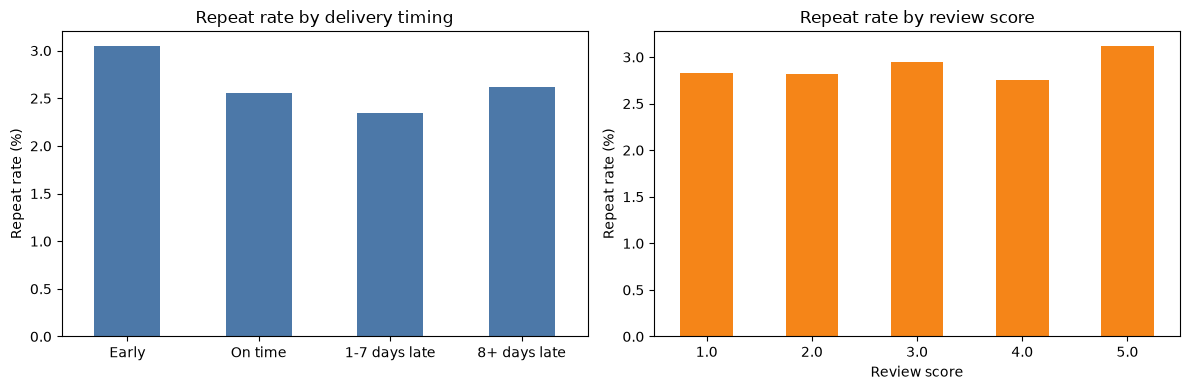

<Figure size 640x480 with 0 Axes>

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

by_delay["repeat_rate_pct"].plot(kind="bar", ax=ax[0], color="#4C78A8")
ax[0].set_title("Repeat rate by delivery timing")
ax[0].set_ylabel("Repeat rate (%)")
ax[0].set_xlabel("")
ax[0].tick_params(axis="x", rotation=0)

by_score["repeat_rate_pct"].plot(kind="bar", ax=ax[1], color="#F58518")
ax[1].set_title("Repeat rate by review score")
ax[1].set_ylabel("Repeat rate (%)")
ax[1].set_xlabel("Review score")
ax[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()
plt.savefig("retention_charts.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
import numpy as np

combo["se"] = np.sqrt(combo["repeat_rate"] * (1 - combo["repeat_rate"]) / combo["customers"])
combo["ci_low_pct"]  = ((combo["repeat_rate"] - 1.96 * combo["se"]) * 100).round(2)
combo["ci_high_pct"] = ((combo["repeat_rate"] + 1.96 * combo["se"]) * 100).round(2)
combo[["customers", "repeat_rate_pct", "ci_low_pct", "ci_high_pct"]]

customers  repeat_rate_pct  ci_low_pct  ci_high_pct
late  bad_review                                                     
False False           78966             3.03        2.91         3.15
      True             8032             3.12        2.74         3.51
True  False            2470             2.87        2.22         3.53
      True             3882             2.22        1.75         2.68

In [18]:
import numpy as np

first["timing"] = np.where(first["delay_days"] > 0, "Late", "On time / early")
t = first.groupby("timing")["repeat"].agg(customers="count", repeat_rate="mean")
t["se"] = np.sqrt(t["repeat_rate"] * (1 - t["repeat_rate"]) / t["customers"])
t["ci_low_pct"]  = ((t["repeat_rate"] - 1.96 * t["se"]) * 100).round(2)
t["ci_high_pct"] = ((t["repeat_rate"] + 1.96 * t["se"]) * 100).round(2)
t["repeat_rate_pct"] = (t["repeat_rate"] * 100).round(2)
t[["customers", "repeat_rate_pct", "ci_low_pct", "ci_high_pct"]]

,customers,repeat_rate_pct,ci_low_pct,ci_high_pct
timing,,,,
Late,6352,2.47,2.09,2.85
On time / early,86998,3.04,2.93,3.15


## Key findings

**1. Late delivery sharply hurts satisfaction.**
Finding: average review score falls from 4.29 (early) to 2.71 (1-7 days late) and 1.69 (8+ days late).
Meaning: delivery performance is the main driver of bad reviews.
Recommendation: prioritise reducing late deliveries and set realistic delivery estimates.

**2. Late delivery is associated with a modest drop in repeat purchases.**
Finding: ~2.5% of customers with a late first order buy again vs 3.05% of those delivered early.
Meaning: delays cost some repeat business, but the effect is small.
Recommendation: proactively contact late-delivery customers (apology, voucher) to recover them.

**3. Retention is low even among satisfied customers.**
Finding: only 3.0% of 93,350 customers ordered again, and even 5-star reviewers return at just 3.12%.
Meaning: fixing delivery alone will not fix retention.
Recommendation: invest in re-engagement (post-purchase emails, coupons, cross-category recommendations).

### Limitations
- Association, not causation.
- ~2 years of data, so recent customers had little time to return.
- 616 customers left no review.
- Repeat rate is based on each customer's first order only.

In [19]:
   by_delay.reset_index().to_csv("delay_vs_repeat.csv", index=False)
   by_score.reset_index().to_csv("score_vs_repeat.csv", index=False)
   combo.reset_index().to_csv("combo_vs_repeat.csv", index=False)